# Linear buckling analysis

This example computes the critical loads and buckling modes of plates and cylindrical panels. It first checks the plate model against the classical closed-form solution of an isotropic plate, then analyses laminated plates with simply supported and free edges, and finally computes a pre-buckling stress state from a static analysis.

In a linear buckling analysis, the pre-buckling state is proportional to a load multiplier $\lambda$. The second variation of the total potential energy has a constitutive part, $\boldsymbol{K}_C$, and a part proportional to the pre-buckling stresses, the geometric stiffness matrix $\boldsymbol{K}_G$. The structure is neutrally stable when

$$
(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0},
$$

an eigenvalue problem solved with `structsolve.lb`, which returns the load multipliers $\lambda$ in increasing order and the buckling modes $\boldsymbol{c}$.

## Constant pre-buckling stress state

The pre-buckling stress state can be given by the constant stress resultants `Nxx`, `Nyy` and `Nxy` of the `Shell` object, in N/m, negative in compression. `Shell.calc_kG` then integrates $\boldsymbol{K}_G$ analytically. With `Nxx = -1` the load multiplier $\lambda$ is the critical $N_{xx}$ in N/m.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb, solve
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_modes(shells_vecs, titles, field='w'):
    """Contour of ``field`` for a list of (shell, Ritz constants)"""
    fig, axes = plt.subplots(1, len(titles), figsize=(4.5*len(titles), 3),
                             squeeze=False)
    for ax, (s, c), title in zip(axes[0], shells_vecs, titles):
        mesh, fields = s.uvw(c, gridx=101, gridy=61)
        cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields[field], levels=30,
                         cmap='coolwarm')
        fig.colorbar(cf, ax=ax)
        ax.set_title(title)
        ax.set_xlabel('$x$ (m)')
        ax.set_ylabel('$y$ (m)')
        ax.set_aspect('equal')
    fig.tight_layout()
    plt.show()

### Check against the closed-form solution of an isotropic plate

A simply supported isotropic plate of length $a$ and width $b$ under a uniform compression $N_{xx}$ buckles at (Timoshenko and Gere, 1961, Chapter 9)

$$
N_{xx,cr} = k \frac{\pi^2 D}{b^2}, \qquad k = \min_m \left(\frac{m b}{a} + \frac{a}{m b}\right)^2, \qquad D = \frac{E h^3}{12(1 - \nu^2)},
$$

with $m$ half-waves along $x$; for $a/b = 2$, $k = 4$ with $m = 2$. An isotropic material is given by `laminaprop = (E, nu)`. For a flat isotropic plate the membrane and bending problems are uncoupled, so the in-plane boundary conditions do not change $\lambda$.

panels: 2067.4741 N/m, closed form: 2067.4741 N/m (k = 4.0000)


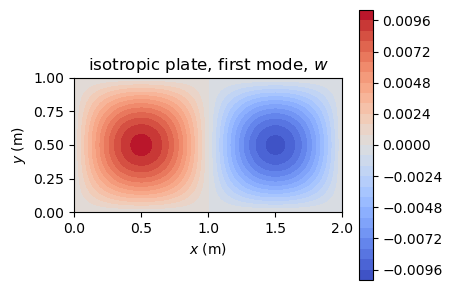

In [2]:
E, nu, h = 70e9, 0.33, 2e-3
s = Shell(model='plate_clpt_donnell', a=2., b=1., stack=[0.], plyt=h,
          laminaprop=(E, nu), m=12, n=12)
s.Nxx = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
D = E*h**3/(12*(1 - nu**2))
ms = np.arange(1, 6)
k = ((ms*s.b/s.a + s.a/(ms*s.b))**2).min()
Ncr = k*np.pi**2*D/s.b**2
print('panels: %.4f N/m, closed form: %.4f N/m (k = %.4f)'
      % (eigvals[0], Ncr, k))
iso_row = ('isotropic plate, $N_{xx,cr}$ (N/m)', eigvals[0], Ncr,
           'closed form, Timoshenko and Gere (1961)')
plot_modes([(s, eigvecs[:, 0])], ['isotropic plate, first mode, $w$'])

### Laminated plates, simply supported

For a symmetric laminate without bending-twisting coupling, $\boldsymbol{B} = \boldsymbol{0}$ and $D_{16} = D_{26} = 0$ (specially orthotropic), simply supported on all edges (SSSS), the modes are again $w = \sin(m\pi x/a)\sin(n\pi y/b)$, and Kassapoglou (2013), Eq. (6.4), p. 126, gives for the compressive loads $N_x$ and $N_y$, positive in compression, and the aspect ratio $AR = a/b$

$$
\pi^2 \left[D_{11} m^4 + 2(D_{12} + 2D_{66}) m^2 n^2 (AR)^2 + D_{22} n^4 (AR)^4\right] = a^2 \left[N_x m^2 + N_y n^2 (AR)^2\right],
$$

minimized over $m$ and $n$; with $N_y = k N_x$ it is Eq. (6.5), p. 127. In `panels` the compression is a negative `Nxx` or `Nyy`, so with `Nxx = -1` the load multiplier $\lambda$ is $N_x$ of this equation, and with `Nyy = -1` it is $N_y$ with $N_x = 0$. The stiffnesses $D_{ij}$, in N m, are those of the `ABD` matrix of the `Shell`.

The plate of $2 \times 1$ m first has the cross-ply laminate $[0/90/90/0]_s$ of carbon/epoxy plies of 0.125 mm, for which the equation is exact. Then the laminate $[0/90/-45/+45]_s$, with $D_{16}, D_{26} \neq 0$: for it Kassapoglou (2013, p. 128) uses the same equation, neglecting $D_{16}$ and $D_{26}$, as an approximation that gives "accurate trends and reasonable buckling predictions" when they are small compared with the other terms; the difference to `panels`, which keeps them, is the effect of the bending-twisting coupling. The cylindrical shell models with a large radius, $r = 10^8$ m, give the plate results.

In [3]:
LAMINA = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)
CROSS_PLY = [0, 90, 90, 0, 0, 90, 90, 0]
QUASI_ISO = [0, 90, -45, +45, +45, -45, 90, 0]


def ncr_orthotropic(D, a, b, load, nmax=10):
    """Kassapoglou (2013), Eq. (6.4): critical load of a specially
    orthotropic SSSS plate under Nx (load='Nxx') or Ny (load='Nyy')"""
    m, n = np.meshgrid(np.arange(1, nmax + 1), np.arange(1, nmax + 1))
    AR = a/b
    num = np.pi**2*(D[0, 0]*m**4 + 2*(D[0, 1] + 2*D[2, 2])*m**2*n**2*AR**2
                    + D[1, 1]*n**4*AR**4)
    den = a**2*(m**2 if load == 'Nxx' else n**2*AR**2)
    return (num/den).min()


def ssss(model, load, stack):
    s = Shell(model=model, a=2., b=1., r=1.e8, m=12, n=12, plyt=0.125e-3,
              stack=stack, laminaprop=LAMINA)
    setattr(s, load, -1.)
    return s


rows = []
modes = {}
for name, stack in (('$[0/90/90/0]_s$', CROSS_PLY),
                    ('$[0/90/-45/+45]_s$', QUASI_ISO)):
    for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
                  'cylshell_clpt_sanders']:
        for load in ('Nxx', 'Nyy'):
            s = ssss(model, load, stack)
            eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
            D = s.ABD[3:6, 3:6]
            ref = ncr_orthotropic(D, s.a, s.b, load)
            print('%-18s %-22s %s: lambda = %.6f N/m, Eq. (6.4): %.6f N/m'
                  % (name.strip('$'), model, load, eigvals[0], ref))
            src = ('Kassapoglou (2013), Eq. (6.4), p. 126' if stack is CROSS_PLY
                   else 'Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128')
            rows.append(('%s, `%s`, $%s$' % (name, model, load), eigvals[0],
                         ref, src))
            if model == 'plate_clpt_donnell':
                modes[(name, load)] = (s, eigvecs[:, 0])
    print('%s: D16/D11 = %.3f, D26/D22 = %.3f' % (name.strip('$'), D[0, 2]/D[0, 0],
                                                  D[1, 2]/D[1, 1]))
results_table(rows)

[0/90/90/0]_s      plate_clpt_donnell     Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m
[0/90/90/0]_s      plate_clpt_donnell     Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m


[0/90/90/0]_s      cylshell_clpt_donnell  Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m
[0/90/90/0]_s      cylshell_clpt_donnell  Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m


[0/90/90/0]_s      cylshell_clpt_sanders  Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m
[0/90/90/0]_s      cylshell_clpt_sanders  Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m
[0/90/90/0]_s: D16/D11 = 0.000, D26/D22 = 0.000


[0/90/-45/+45]_s   plate_clpt_donnell     Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   plate_clpt_donnell     Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m


[0/90/-45/+45]_s   cylshell_clpt_donnell  Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   cylshell_clpt_donnell  Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m


[0/90/-45/+45]_s   cylshell_clpt_sanders  Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   cylshell_clpt_sanders  Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m
[0/90/-45/+45]_s: D16/D11 = -0.035, D26/D22 = -0.059


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $[0/90/90/0]_s$, `plate_clpt_donnell`, $Nxx$ | 145.76 | 145.76 | +1.25e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `plate_clpt_donnell`, $Nyy$ | 61.865 | 61.865 | +7.24e-15 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_donnell`, $Nxx$ | 145.76 | 145.76 | +1.68e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_donnell`, $Nyy$ | 61.865 | 61.865 | +1.01e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_sanders`, $Nxx$ | 145.76 | 145.76 | +1.68e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_sanders`, $Nyy$ | 61.865 | 61.865 | +1.01e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/-45/+45]_s$, `plate_clpt_donnell`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `plate_clpt_donnell`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_donnell`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_donnell`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_sanders`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_sanders`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |

The cross-ply plate agrees with the exact solution to the digits printed. The quasi-isotropic plate, with $|D_{16}/D_{11}| = 0.035$ and $|D_{26}/D_{22}| = 0.059$, buckles at a load 0.8% ($N_{xx}$) and 0.5% ($N_{yy}$) lower than the approximation without $D_{16}$ and $D_{26}$: the bending-twisting coupling skews the half-waves, as the mode plots below show, and lowers the critical load, so the approximation is slightly unconservative here.

### Plate with one free edge

The plate of $1 \times 0.5$ m with the unsymmetric laminate $[0/90/-45/+45]$ has one free edge: $u$, $v$ and $w$ are released at $y = b$ (`y2u`, `y2v`, `y2w`) for $N_{xx}$, and at $x = a$ for $N_{yy}$. No published value was found for this laminate with a free edge; the reference values are regression values of the panels unit test `tests/tests_shell/test_lb.py`, checked there within an absolute tolerance of 0.1 N/m.

In [4]:
def one_free_edge(model, load):
    s = Shell(model=model, a=1., b=0.5, r=1.e8, m=12, n=13, plyt=0.125e-3,
              stack=[0, 90, -45, +45], laminaprop=LAMINA)
    edge = 'y2' if load == 'Nxx' else 'x2'
    for field in 'uvw':
        setattr(s, edge + field, 1)
    setattr(s, load, -1.)
    return s


REF = {'Nxx': 15.8106238, 'Nyy': 13.9105}
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders']:
    for load, ref in REF.items():
        s = one_free_edge(model, load)
        eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
        print('%-22s free edge %s: lambda = %.6f N/m' % (model, load, eigvals[0]))
        rows.append(('`%s`, free edge, $%s$' % (model, load), eigvals[0], ref,
                     'regression value, `test_lb.py`'))
        if model == 'plate_clpt_donnell':
            modes[('free edge', load)] = (s, eigvecs[:, 0])
results_table(rows)

plate_clpt_donnell     free edge Nxx: lambda = 15.762885 N/m
plate_clpt_donnell     free edge Nyy: lambda = 13.910509 N/m


cylshell_clpt_donnell  free edge Nxx: lambda = 15.762896 N/m
cylshell_clpt_donnell  free edge Nyy: lambda = 13.910505 N/m


cylshell_clpt_sanders  free edge Nxx: lambda = 15.762896 N/m


cylshell_clpt_sanders  free edge Nyy: lambda = 13.910505 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, free edge, $Nxx$ | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `plate_clpt_donnell`, free edge, $Nyy$ | 13.9105 | 13.9105 | +6.59e-07 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, free edge, $Nxx$ | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, free edge, $Nyy$ | 13.9105 | 13.9105 | +3.49e-07 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, free edge, $Nxx$ | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, free edge, $Nyy$ | 13.9105 | 13.9105 | +3.49e-07 | regression value, `test_lb.py` |

The first buckling modes of the plate model: the SSSS plates under $N_{xx}$, cross-ply and quasi-isotropic, and the plate with the free edge, which buckles with the largest deflection along the free edge.

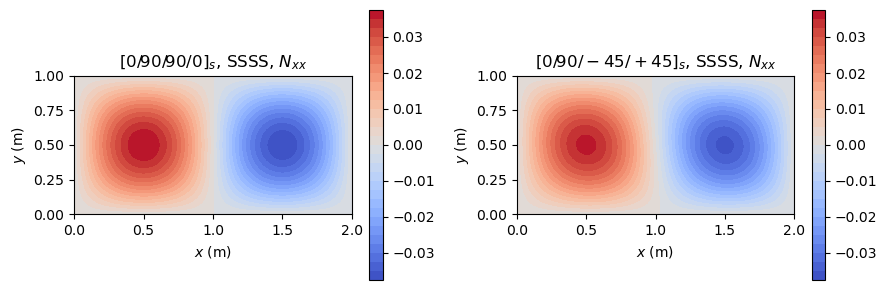

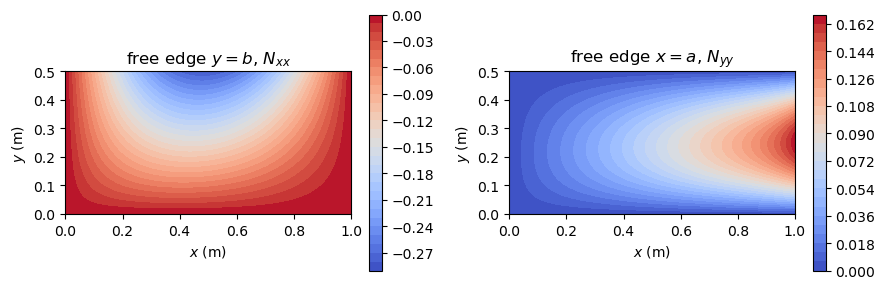

In [5]:
plot_modes([modes[('$[0/90/90/0]_s$', 'Nxx')], modes[('$[0/90/-45/+45]_s$', 'Nxx')]],
           ['$[0/90/90/0]_s$, SSSS, $N_{xx}$', '$[0/90/-45/+45]_s$, SSSS, $N_{xx}$'])
plot_modes([modes[('free edge', 'Nxx')], modes[('free edge', 'Nyy')]],
           ['free edge $y = b$, $N_{xx}$', 'free edge $x = a$, $N_{yy}$'])

### Combined loads on a curved panel

Combined load cases are given by more than one stress resultant, here compression and shear, $N_{xx} = N_{xy} = -1$ N/m, on an isotropic aluminium cylindrical panel of radius $r = 2$ m with Donnell's kinematics, simply supported. The load multiplier scales both resultants. No published value was found for this case.

first load multipliers: [4651.652 4699.137 5531.811 5587.955]


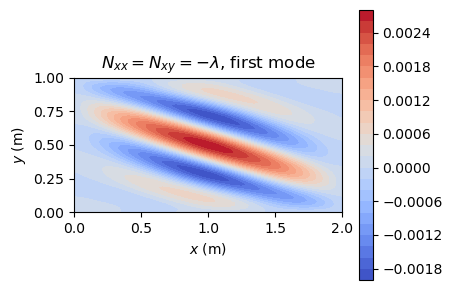

In [6]:
s = Shell(model='cylshell_clpt_donnell', a=2., b=1., r=2., m=12, n=12,
          stack=[0.], plyt=1e-3, laminaprop=(70e9, 0.33))
s.Nxx = -1.
s.Nxy = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
print('first load multipliers:', np.round(eigvals[:4], 3))
plot_modes([(s, eigvecs[:, 0])], ['$N_{xx} = N_{xy} = -\\lambda$, first mode'])

## Pre-buckling stress state from a static analysis

$\boldsymbol{K}_G$ can also be computed from the Ritz constants $\boldsymbol{c}_0$ of a linear static solution, `Shell.calc_kG(c=c0)`, which integrates the pre-buckling stress field numerically. The stresses then follow the boundary conditions instead of being assumed constant.

The plate of $8 \times 4$ m with the cross-ply laminate $[0/90/90/0]$ is compressed by a load of 1 N/m distributed along $x = a$. The in-plane boundary conditions let the edges move: $u$ is free except at $x = 0$, and $v$ is constrained only along $x = 0$. The critical $N_{xx}$ is computed first with a constant $N_{xx} = -1$ and then with the pre-buckling state of the static solution under the same load. The laminate is specially orthotropic and $w$ is simply supported at all edges, so both are compared with Kassapoglou (2013), Eq. (6.4). The static state is not exactly uniform: $v = 0$ along $x = 0$ restrains the Poisson expansion there, and the critical load from it is 0.03% lower.

In [7]:
def plate_8x4(model, stack=(0, 90, 90, 0)):
    p = Shell(model=model, a=8., b=4., r=1.e8, m=8, n=9, plyt=0.125e-3,
              stack=list(stack), laminaprop=LAMINA)
    p.x1ur = 1
    p.x2u = p.x2ur = 1
    p.y1u = p.y1ur = p.y2u = p.y2ur = 1
    p.x1v = p.x1vr = 0
    p.x2v = p.x2vr = p.y1v = p.y1vr = p.y2v = p.y2vr = 1
    return p


def lb_constant_and_static(p):
    p.Nxx = -1.
    k0 = p.calc_kC(silent=True)
    eig_cte, _ = lb(k0, p.calc_kG(silent=True), silent=True)
    p.Nxx = 0.
    p.add_distr_load_fixed_x(p.a, lambda y: -1., None, None)
    c0 = solve(k0, p.calc_fext(silent=True), silent=True)
    eig_static, modes = lb(k0, p.calc_kG(c=c0, silent=True), silent=True)
    return eig_cte[0], eig_static[0], c0, modes


import warnings
warnings.showwarning = lambda message, category, *args, **kwargs: print(
    '%s: %s' % (category.__name__, message))
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    p = plate_8x4(model)
    lbd_cte, lbd_static, c0, modes = lb_constant_and_static(p)
    ref = ncr_orthotropic(p.ABD[3:6, 3:6], p.a, p.b, 'Nxx')
    print('%-22s constant Nxx: %.5f, from the static solution: %.5f, '
          'Eq. (6.4): %.5f N/m' % (model, lbd_cte, lbd_static, ref))
    rows.append(('`%s`, constant $N_{xx}$' % model, lbd_cte, ref,
                 'Kassapoglou (2013), Eq. (6.4), p. 126'))
    rows.append(('`%s`, $N_{xx}$ from static' % model, lbd_static, ref,
                 'Kassapoglou (2013), Eq. (6.4), p. 126'))
results_table(rows)

plate_clpt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m
cylshell_clpt_donnell  constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


cylshell_clpt_sanders  constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


plate_fsdt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


plate_tsdt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.70e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_clpt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.72e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_sanders`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.72e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_sanders`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_fsdt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | -8.42e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_fsdt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_tsdt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | -6.40e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_tsdt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |

For some models, `structsolve.lb` may warn that its sparse eigensolvers did not reach the required accuracy, and then solves the problem with its dense solver instead; the results are not affected.

With an unsymmetric laminate, $\boldsymbol{B} \neq \boldsymbol{0}$, the in-plane load of the static solution also bends the plate and changes the pre-buckling stresses, and the two pre-buckling states give different critical loads; no closed form exists then. For the laminate $[0/90/90/0/-45/+45]$:

In [8]:
lbd_cte, lbd_static, _, _ = lb_constant_and_static(
    plate_8x4('plate_clpt_donnell', stack=(0, 90, 90, 0, -45, +45)))
print('constant Nxx: %.5f N/m, from the static solution: %.5f N/m (%+.2f%%)'
      % (lbd_cte, lbd_static, 100*(lbd_static/lbd_cte - 1)))

constant Nxx: 4.47698 N/m, from the static solution: 4.39212 N/m (-1.90%)


The pre-buckling stress resultant $N_{xx}$ of the static solution, and the first buckling mode computed with it, for the last model of the cross-ply loop:

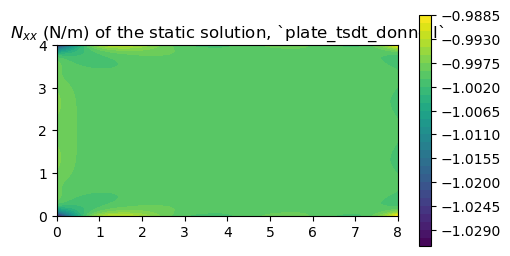

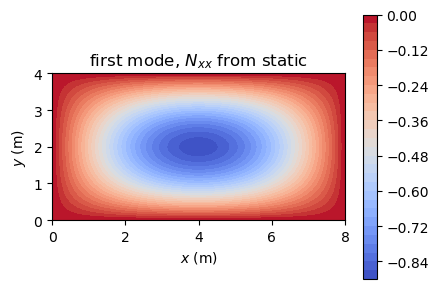

In [9]:
mesh, fields = p.stress(c0, gridx=101, gridy=61)
fig, ax = plt.subplots(figsize=(5.5, 3))
cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields['Nxx'], levels=30,
                 cmap='viridis')
fig.colorbar(cf, ax=ax)
ax.set_title('$N_{xx}$ (N/m) of the static solution, `%s`' % p.model)
ax.set_aspect('equal')
plt.show()
plot_modes([(p, modes[:, 0])], ['first mode, $N_{xx}$ from static'])

## Discussion

The isotropic plate and the specially orthotropic cross-ply plates agree with the closed forms, with a constant pre-buckling state and with the state of the static solution, for the plate models and for the cylindrical shell models with a large radius. The pre-buckling state of the static solution lowers the critical load by 1.9% for the unsymmetric laminate. The bending-twisting coupling of the quasi-isotropic laminate lowers its critical load below the approximation of Kassapoglou (2013) that neglects $D_{16}$ and $D_{26}$. The plate with one free edge and the curved panel under combined loads have no published reference among the sources used here.

## References

1. S. P. Timoshenko and J. M. Gere, "Theory of Elastic Stability". 2nd ed., McGraw-Hill, New York, 1961.
2. C. Kassapoglou, "Design and Analysis of Composite Structures: With Applications to Aerospace Structures". 2nd ed., Wiley, Chichester, 2013. https://doi.org/10.1002/9781118536933.
3. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.